# KDE numerical foundations for the thesis

Run the two sections in order: the Fourier-error figure and the runtime table.
Raw settings and samples retain their experiment names; every displayed figure
is also exported under `outputs/pdfs/02_kde_numerics/`.

Source: [KDE chapter, numerical approximation](../../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex).

Reusable functions: [`numerical_experiments.py`](../kde_tools/numerical_experiments.py).
Experiment settings and calls are below. Every displayed figure is saved automatically as a PDF.


## Fourier approximation error


In [ ]:
from _setup import setup_notebook
import csv
import hashlib
import json
import matplotlib.pyplot as plt
import numpy as np
import os
from kde_tools.density import exact_gaussian_kde_l2_gram
from kde_tools.fourier.similarities import (
    DEFAULT_FREQUENCY_CUTOFF,
    DEFAULT_FREQUENCY_INTERVALS,
    FOURIER_L2_METHOD_VERSION,
    gaussian_kde_l2_gram_fourier,
)
from kde_tools.numerical_experiments import (
    prepare_runtime_run,
    run_fourier_error_experiment,
    save_runtime_comparison,
    summarize_fourier_error,
)
from kde_tools.thesis_exports import copy_thesis_pdf
from threadpoolctl import threadpool_info, threadpool_limits
from time import perf_counter

paths = setup_notebook("02_kde_numerics")
code_directory = paths.code
pdf_output_directory = paths.pdfs
notebook_name = "g_rs_error_vs_k_repeated_samples"


In [ ]:
n = 200
realizations = 200
seed = 20261024
N = 50
h_min, h_max = (0.01, 2.0)
frequency_cutoff = 450.0
K_candidates = np.arange(64, 2304 + 1, 16, dtype=int)
highlight_K = 1376
absolute_tolerance = 1e-08
workers = min(4, os.cpu_count() or 1)
samples = np.stack([np.random.default_rng(seed + m).normal(size=n) for m in range(realizations)])
bandwidths = np.geomspace(h_min, h_max, N)
settings = {
    "sample_distribution": "standard_normal",
    "realizations": realizations,
    "n": n,
    "seed": seed,
    "seed_rule": "seed + zero_based_sample_index",
    "N": N,
    "h_min": h_min,
    "h_max": h_max,
    "bandwidth_grid": "geometric",
    "frequency_cutoff": frequency_cutoff,
    "K_candidates": K_candidates.tolist(),
    "highlight_K": highlight_K,
    "absolute_tolerance": absolute_tolerance,
    "K_convention": "trapezoidal intervals; frequency_points = K + 1",
    "per_sample_error": "max over all r,s including diagonal of abs(G_exact - G_approx)",
    "summary_curves": ["maximum of per-sample errors"],
    "reference": "exact_gaussian_kde_l2_gram_float64",
    "method_version": FOURIER_L2_METHOD_VERSION,
    "numpy_version": np.__version__,
}
configuration_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:12]
data_directory = code_directory / "outputs" / "data" / notebook_name / configuration_id
image_directory = code_directory / "outputs" / "images" / notebook_name
data_directory.mkdir(parents=True, exist_ok=True)
image_directory.mkdir(parents=True, exist_ok=True)
(data_directory / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")
print(f"Configuration {configuration_id}: {realizations} independent samples of size {n}.")
print(f"Omega={frequency_cutoff:g}; {N} geometric bandwidths in [{h_min:g}, {h_max:g}].")
print(f"{len(K_candidates)} K values; up to {workers} calculation threads.")


Configuration 661f8de39b4d: 200 independent samples of size 200.
Omega=450; 50 geometric bandwidths in [0.01, 2].
141 K values; up to 4 calculation threads.


In [ ]:
(
    per_sample_errors,
    worst_indices,
    exact_grams,
    elapsed_seconds,
    cached_directory,
    calculation_directory,
) = run_fourier_error_experiment(
    K_candidates=K_candidates,
    N=N,
    bandwidths=bandwidths,
    data_directory=data_directory,
    frequency_cutoff=frequency_cutoff,
    realizations=realizations,
    samples=samples,
    settings=settings,
    workers=workers,
)


Reused all 200 verified samples from 661f8de39b4d; no simulations rerun.


32

In [ ]:
maximum_errors, report = summarize_fourier_error(
    K_candidates=K_candidates,
    N=N,
    absolute_tolerance=absolute_tolerance,
    cached_directory=cached_directory,
    configuration_id=configuration_id,
    data_directory=data_directory,
    elapsed_seconds=elapsed_seconds,
    frequency_cutoff=frequency_cutoff,
    highlight_K=highlight_K,
    n=n,
    per_sample_errors=per_sample_errors,
    realizations=realizations,
    workers=workers,
)


First tested K with maximum E_K <= 1e-08: 1376
At K=1536: maximum error=1.58663055e-10.
Samples above the target at K=1536: 0/200.


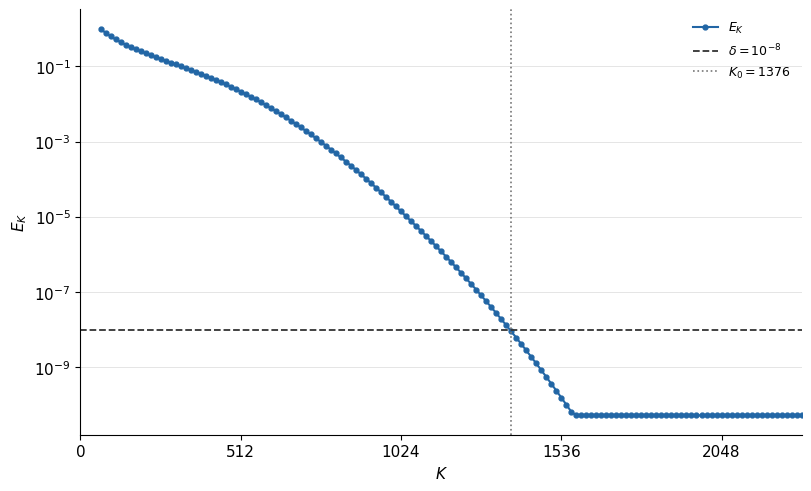

In [ ]:
with plt.rc_context(
    {
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
    }
):
    fig, ax = plt.subplots(figsize=(8.0, 4.8), layout="constrained")
    ax.plot(
        K_candidates,
        maximum_errors,
        color="#2266a5",
        linewidth=1.5,
        marker="o",
        markersize=3.5,
        label=r"$E_K$",
    )
    ax.axhline(
        absolute_tolerance, color="#333333", linestyle="--", linewidth=1.3, label=r"$\delta=10^{-8}$"
    )
    ax.axvline(
        highlight_K,
        color="#777777",
        linestyle=":",
        linewidth=1.2,
        label=rf"$K_0={highlight_K}$",
    )
    ax.set_yscale("log")
    ax.set_xlim(0, K_candidates[-1])
    ax.set_xticks([0, 512, 1024, 1536, 2048])
    ax.set_xlabel("$K$")
    ax.set_ylabel("$E_K$")
    ax.grid(axis="y", which="major", color="#e5e5e5", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.legend(loc="upper right", frameon=False, fontsize=9)
    png_path = image_directory / "g_rs_error_vs_k_maximum.png"
    fig.savefig(png_path, dpi=200, bbox_inches="tight")
    fig.savefig(
        pdf_output_directory / "001_maximum_error_over_200_samples_at_omega_450_n_200_n_50_h_in_0_01_2_geometric_ban.pdf",
        format="pdf", bbox_inches="tight",
    )
    plt.show()
if n == 200 and N == 50 and (realizations == 200):
    copy_thesis_pdf(
        pdf_output_directory,
        "g_rs_error_vs_k_repeated_samples",
        "001_maximum_error_over_200_samples_at_omega_450_n_200_n_50_h_in_0_01_2_geometric_ban.pdf",
    )


## Exact versus Fourier runtime table


In [ ]:
thread_environment_keys = (
    "VECLIB_MAXIMUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "OMP_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
)
for variable in thread_environment_keys:
    os.environ[variable] = "1"
notebook_name = "g_rs_runtime_comparison"


In [ ]:
n = 200
realizations = 100
N = 50
h_min, h_max = (0.01, 2.0)
frequency_cutoff = DEFAULT_FREQUENCY_CUTOFF
K = DEFAULT_FREQUENCY_INTERVALS
seed = 2026102600
warmup_calls_per_method = 3
absolute_tolerance = 1e-08
bandwidths = np.geomspace(h_min, h_max, N)
samples = np.stack(
    [
        np.random.default_rng(seed + sample_index).normal(size=n)
        for sample_index in range(realizations)
    ]
)
warmup_sample = np.random.default_rng(seed + 1000000).normal(size=n)
data_directory, settings, configuration_id, run_id = prepare_runtime_run(
    K=K,
    N=N,
    absolute_tolerance=absolute_tolerance,
    bandwidths=bandwidths,
    code_directory=code_directory,
    frequency_cutoff=frequency_cutoff,
    h_max=h_max,
    h_min=h_min,
    n=n,
    notebook_name=notebook_name,
    realizations=realizations,
    samples=samples,
    seed=seed,
    warmup_calls_per_method=warmup_calls_per_method,
)


100 samples of size 200; 50 bandwidths; Omega=450; K=1536.
Results: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/g_rs_runtime_comparison/1a13a92c437d/20261029T214514049437Z_c252e9


In [ ]:
exact_seconds = np.empty(realizations)
fourier_seconds = np.empty(realizations)
exact_grams = np.empty((realizations, N, N))
fourier_grams = np.empty_like(exact_grams)
per_sample_max_errors = np.empty(realizations)
worst_indices = np.empty((realizations, 2), dtype=int)
with threadpool_limits(limits=1):
    for _ in range(warmup_calls_per_method):
        exact_gaussian_kde_l2_gram(warmup_sample, bandwidths)
        gaussian_kde_l2_gram_fourier(
            warmup_sample,
            bandwidths,
            frequency_cutoff=frequency_cutoff,
            frequency_points=int(K) + 1,
        )
    active_threadpools = threadpool_info()
    experiment_start = perf_counter()
    for sample_index, current_sample in enumerate(samples):
        method_order = ("exact", "fourier") if sample_index % 2 == 0 else ("fourier", "exact")
        for method in method_order:
            if method == "exact":
                start = perf_counter()
                current_exact = exact_gaussian_kde_l2_gram(current_sample, bandwidths)
                duration = perf_counter() - start
                exact_seconds[sample_index] = duration
                exact_grams[sample_index] = current_exact
            else:
                start = perf_counter()
                current_fourier = gaussian_kde_l2_gram_fourier(
                    current_sample,
                    bandwidths,
                    frequency_cutoff=frequency_cutoff,
                    frequency_points=int(K) + 1,
                )
                duration = perf_counter() - start
                fourier_seconds[sample_index] = duration
                fourier_grams[sample_index] = current_fourier
        difference = np.abs(current_fourier - current_exact)
        r, s = np.unravel_index(np.argmax(difference), difference.shape)
        worst_indices[sample_index] = (r, s)
        per_sample_max_errors[sample_index] = difference[r, s]
        if (sample_index + 1) % 10 == 0:
            print(
                f"Completed {sample_index + 1}/{realizations} samples ({perf_counter() - experiment_start:.1f} s).",
                flush=True,
            )
    experiment_seconds = perf_counter() - experiment_start
np.savez_compressed(
    data_directory / "per_sample_results.npz",
    exact_seconds=exact_seconds,
    fourier_seconds=fourier_seconds,
    maximum_absolute_errors=per_sample_max_errors,
    worst_indices=worst_indices,
    exact_grams=exact_grams,
    fourier_grams=fourier_grams,
)
with (data_directory / "per_sample_results.csv").open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(
        [
            "sample_l_one_based",
            "seed",
            "first_method",
            "exact_seconds",
            "fourier_seconds",
            "maximum_absolute_error",
            "worst_r_zero_based",
            "worst_s_zero_based",
            "h_r",
            "h_s",
        ]
    )
    for sample_index in range(realizations):
        r, s = worst_indices[sample_index]
        writer.writerow(
            [
                sample_index + 1,
                seed + sample_index,
                "exact" if sample_index % 2 == 0 else "fourier",
                exact_seconds[sample_index],
                fourier_seconds[sample_index],
                per_sample_max_errors[sample_index],
                int(r),
                int(s),
                bandwidths[r],
                bandwidths[s],
            ]
        )


Completed 10/100 samples (2.9 s).
Completed 20/100 samples (5.8 s).
Completed 30/100 samples (9.0 s).
Completed 40/100 samples (11.9 s).
Completed 50/100 samples (14.8 s).
Completed 60/100 samples (17.7 s).
Completed 70/100 samples (20.6 s).
Completed 80/100 samples (23.4 s).
Completed 90/100 samples (26.2 s).
Completed 100/100 samples (29.5 s).


In [ ]:
report = save_runtime_comparison(
    K=K,
    N=N,
    absolute_tolerance=absolute_tolerance,
    active_threadpools=active_threadpools,
    bandwidths=bandwidths,
    code_directory=code_directory,
    configuration_id=configuration_id,
    data_directory=data_directory,
    exact_grams=exact_grams,
    exact_seconds=exact_seconds,
    experiment_seconds=experiment_seconds,
    fourier_grams=fourier_grams,
    fourier_seconds=fourier_seconds,
    frequency_cutoff=frequency_cutoff,
    n=n,
    notebook_name=notebook_name,
    per_sample_max_errors=per_sample_max_errors,
    realizations=realizations,
    run_id=run_id,
    seed=seed,
    settings=settings,
    thread_environment_keys=thread_environment_keys,
)


| Method | Mean time per complete matrix (ms) | Maximum absolute error |
| --- | ---: | ---: |
| Exact Gaussian formula | 284.126 | Reference |
| Fourier approximation | 10.450 | 9.182e-11 |

100 standard-normal samples, n=200; N=50 geometric bandwidths in [0.01, 2]; Omega=450, K=1536 intervals. The Fourier implementation is 27.19 times faster by the ratio of mean times. The error is the maximum over all 250,000 matrix entries, including diagonals. Measured on Apple M1 (Darwin 25.5.0); timings are machine dependent.


Worst error: 9.181809479397e-11; sample l=44, h=2, s=2.
Samples above 1e-08: 0/100.
LaTeX table: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/g_rs_runtime_comparison/1a13a92c437d/20261029T214514049437Z_c252e9/runtime_comparison_table.tex
